# Homework 7 – DSCI 552

## 1. Multi-Class and Multi-Label Classification Using SVMs

### 1(a) Data Preparation and Train-Test Split

In [1]:
import pandas as pd

df = pd.read_csv("Data/Frogs_MFCCs.csv")

print(df.shape)
df.head()

(7195, 26)


,MFCCs_ 1,MFCCs_ 2,MFCCs_ 3,MFCCs_ 4,MFCCs_ 5,MFCCs_ 6,MFCCs_ 7,MFCCs_ 8,MFCCs_ 9,MFCCs_10,...,MFCCs_17,MFCCs_18,MFCCs_19,MFCCs_20,MFCCs_21,MFCCs_22,Family,Genus,Species,RecordID
0,1.0,0.152936,-0.105586,0.200722,0.317201,0.260764,0.100945,-0.150063,-0.171128,0.124676,...,-0.108351,-0.077623,-0.009568,0.057684,0.118680,0.014038,Leptodactylidae,Adenomera,AdenomeraAndre,1
1,1.0,0.171534,-0.098975,0.268425,0.338672,0.268353,0.060835,-0.222475,-0.207693,0.170883,...,-0.090974,-0.056510,-0.035303,0.020140,0.082263,0.029056,Leptodactylidae,Adenomera,AdenomeraAndre,1
2,1.0,0.152317,-0.082973,0.287128,0.276014,0.189867,0.008714,-0.242234,-0.219153,0.232538,...,-0.050691,-0.023590,-0.066722,-0.025083,0.099108,0.077162,Leptodactylidae,Adenomera,AdenomeraAndre,1
3,1.0,0.224392,0.118985,0.329432,0.372088,0.361005,0.015501,-0.194347,-0.098181,0.270375,...,-0.136009,-0.177037,-0.130498,-0.054766,-0.018691,0.023954,Leptodactylidae,Adenomera,AdenomeraAndre,1
4,1.0,0.087817,-0.068345,0.306967,0.330923,0.249144,0.006884,-0.265423,-0.172700,0.266434,...,-0.048885,-0.053074,-0.088550,-0.031346,0.108610,0.079244,Leptodactylidae,Adenomera,AdenomeraAndre,1


In [2]:
from sklearn.model_selection import train_test_split

# Features and labels
X = df.filter(regex=r"^MFCCs_")
y = df[["Family", "Genus", "Species"]]

# Split into 70% training and 30% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training set: (5036, 22)
Testing set: (2159, 22)
Training labels: (5036, 3)
Testing labels: (2159, 3)


### 1(b)i Exact Match and Hamming Score/Loss

Exact Match Ratio measures the proportion of samples for which all three labels (Family, Genus, and Species) are predicted correctly.

Hamming Loss measures the fraction of incorrectly predicted labels among all labels.

Hamming Score measures the fraction of correctly predicted labels. In this problem, each sample has exactly three categorical labels, so Hamming Score = 1 - Hamming Loss.

A higher Exact Match Ratio and Hamming Score indicate better classification performance, while a lower Hamming Loss indicates better performance.

In [3]:
import numpy as np

def evaluate_model(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    exact_match = np.mean(np.all(y_true == y_pred, axis=1))
    hloss = np.mean(y_true != y_pred)
    hscore = 1 - hloss

    return {
        "Exact Match Ratio": exact_match,
        "Hamming Score": hscore,
        "Hamming Loss": hloss
    }

print("Evaluation metrics function defined successfully.")

Evaluation metrics function defined successfully.


### 1(b)ii Gaussian Kernel SVM with 10-Fold Cross Validation

We train a separate SVM with a Gaussian (RBF) kernel for each of Family, Genus and Species, using one-vs-rest classifiers (binary relevance). The penalty weight C and the kernel parameter gamma (gamma = 1 / (2σ²), so a larger gamma means a narrower kernel) are selected with 10-fold cross-validation. The models are then evaluated on the test set with Exact Match Ratio, Hamming Score and Hamming Loss.

**Choosing the parameter ranges.** A first search over C ∈ {0.1, 1, 10, 100} and gamma ∈ {0.001, 0.01, 0.1, 1} selected gamma = 1 for every label, and C = 100 for Family. Both are the largest values in that grid, so the true optimum could lie outside it. Following the rule of thumb in the homework, we ran a wide preliminary search (5-fold CV, C from 0.1 to 10⁴ and gamma from 0.1 to 10) to find where accuracy is high:

- **Raw attributes:** accuracy peaks around gamma ≈ 3 and falls again at gamma = 10. It stays well above 70% for C ≥ 1 and stops changing for C above about 100.
- **Standardized attributes:** standardizing makes each feature's variance 1, so the distances between samples are much larger. Accuracy is highest at the smallest gamma tried (0.1) and drops sharply for gamma ≥ 1, so smaller gamma values must also be searched.

The final grids below use log-spaced values for C and finer, roughly linear steps for gamma, and they cover the optimum from both sides. The code checks that the selected parameters are not on the edge of the grid. As suggested in the homework, we report results for both raw and standardized attributes.

In [4]:
from sklearn.svm import SVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

labels = ["Family", "Genus", "Species"]

# Ranges chosen from the preliminary wide search described above
rbf_settings = {
    "raw": {
        "steps": [],
        "grid": {
            "classifier__estimator__C": [0.1, 1, 10, 100, 1000, 10000],
            "classifier__estimator__gamma": [0.5, 1, 1.5, 2, 2.5, 3, 4, 5, 7, 10],
        },
    },
    "standardized": {
        "steps": [("scaler", StandardScaler())],
        "grid": {
            "classifier__estimator__C": [0.1, 1, 10, 100, 1000, 10000],
            "classifier__estimator__gamma": [0.005, 0.01, 0.02, 0.03, 0.05, 0.07, 0.1, 0.2, 0.3],
        },
    },
}

def fit_rbf_svms(setting):
    models, best_params = {}, {}
    predictions = pd.DataFrame(index=y_test.index)
    grid_values = rbf_settings[setting]["grid"]

    for label in labels:
        pipeline = Pipeline(
            rbf_settings[setting]["steps"]
            + [("classifier", OneVsRestClassifier(SVC(kernel="rbf")))]
        )
        grid = GridSearchCV(pipeline, grid_values, cv=10, scoring="accuracy", n_jobs=-1)
        grid.fit(X_train, y_train[label])

        models[label] = grid.best_estimator_
        best_params[label] = grid.best_params_
        predictions[label] = grid.predict(X_test)

        best_C = grid.best_params_["classifier__estimator__C"]
        best_gamma = grid.best_params_["classifier__estimator__gamma"]
        gammas = grid_values["classifier__estimator__gamma"]
        Cs = grid_values["classifier__estimator__C"]
        print(f"[{setting}] {label}: best C = {best_C}, best gamma = {best_gamma}, "
              f"10-fold CV accuracy = {grid.best_score_:.4f}")
        if best_gamma in (gammas[0], gammas[-1]):
            print("   WARNING: best gamma is on the edge of the grid")
        if best_C == Cs[0]:
            print("   WARNING: best C is on the lower edge of the grid")

        # CV accuracy over the whole grid (rows = C, columns = gamma)
        cv_table = pd.DataFrame(grid.cv_results_).pivot_table(
            index="param_classifier__estimator__C",
            columns="param_classifier__estimator__gamma",
            values="mean_test_score",
        )
        cv_table.index.name, cv_table.columns.name = "C", "gamma"
        display(cv_table.round(4))

    return models, best_params, predictions

rbf_models, rbf_best_params, rbf_predictions = fit_rbf_svms("raw")
rbf_results = evaluate_model(y_test, rbf_predictions)

rbf_std_models, rbf_std_best_params, rbf_std_predictions = fit_rbf_svms("standardized")
rbf_std_results = evaluate_model(y_test, rbf_std_predictions)

print("Test-set results of the Gaussian-kernel SVMs:")
display(pd.DataFrame({
    "RBF SVM (raw)": rbf_results,
    "RBF SVM (standardized)": rbf_std_results,
}).T.round(4))

[raw] Family: best C = 10, best gamma = 2.5, 10-fold CV accuracy = 0.9936


gamma,0.5,1.0,1.5,2.0,2.5,3.0,4.0,5.0,7.0,10.0
C,,,,,,,,,,
0.1,0.9458,0.9601,0.9664,0.9710,0.9724,0.9726,0.9780,0.9797,0.9789,0.9768
1.0,0.9706,0.9813,0.9897,0.9913,0.9919,0.9923,0.9919,0.9911,0.9885,0.9867
10.0,0.9869,0.9913,0.9927,0.9934,0.9936,0.9936,0.9934,0.9925,0.9901,0.9873
100.0,0.9899,0.9921,0.9923,0.9932,0.9932,0.9931,0.9934,0.9929,0.9901,0.9873
1000.0,0.9897,0.9915,0.9923,0.9932,0.9932,0.9931,0.9934,0.9929,0.9901,0.9873
10000.0,0.9897,0.9915,0.9923,0.9932,0.9932,0.9931,0.9934,0.9929,0.9901,0.9873


[raw] Genus: best C = 10, best gamma = 2.5, 10-fold CV accuracy = 0.9919


gamma,0.5,1.0,1.5,2.0,2.5,3.0,4.0,5.0,7.0,10.0
C,,,,,,,,,,
0.1,0.9118,0.9327,0.9440,0.9563,0.9647,0.9684,0.9720,0.9726,0.9700,0.9583
1.0,0.9674,0.9811,0.9871,0.9889,0.9899,0.9899,0.9901,0.9893,0.9865,0.9831
10.0,0.9863,0.9901,0.9911,0.9911,0.9919,0.9919,0.9915,0.9903,0.9891,0.9843
100.0,0.9885,0.9901,0.9905,0.9911,0.9913,0.9911,0.9915,0.9903,0.9891,0.9843
1000.0,0.9897,0.9899,0.9905,0.9911,0.9913,0.9911,0.9915,0.9903,0.9891,0.9843
10000.0,0.9897,0.9899,0.9905,0.9911,0.9913,0.9911,0.9915,0.9903,0.9891,0.9843


[raw] Species: best C = 10, best gamma = 2.5, 10-fold CV accuracy = 0.9915


gamma,0.5,1.0,1.5,2.0,2.5,3.0,4.0,5.0,7.0,10.0
C,,,,,,,,,,
0.1,0.9112,0.9339,0.9454,0.9583,0.9670,0.9696,0.9722,0.9732,0.9722,0.9645
1.0,0.9704,0.9829,0.9871,0.9893,0.9901,0.9899,0.9899,0.9901,0.9875,0.9841
10.0,0.9871,0.9899,0.9905,0.9905,0.9915,0.9915,0.9911,0.9903,0.9881,0.9837
100.0,0.9885,0.9889,0.9897,0.9905,0.9915,0.9909,0.9913,0.9907,0.9881,0.9837
1000.0,0.9883,0.9889,0.9897,0.9905,0.9915,0.9909,0.9913,0.9907,0.9881,0.9837
10000.0,0.9883,0.9889,0.9897,0.9905,0.9915,0.9909,0.9913,0.9907,0.9881,0.9837


... (4 outputs left out)

[standardized] Species: best C = 10, best gamma = 0.05, 10-fold CV accuracy = 0.9907


gamma,0.005,0.010,0.020,0.030,0.050,0.070,0.100,0.200,0.300
C,,,,,,,,,
0.1,0.8876,0.9096,0.9307,0.9416,0.9611,0.9676,0.9696,0.9603,0.9494
1.0,0.9474,0.9660,0.9793,0.9843,0.9881,0.9881,0.9871,0.9825,0.9724
10.0,0.9811,0.9855,0.9889,0.9895,0.9907,0.9895,0.9885,0.9825,0.9766
100.0,0.9863,0.9877,0.9891,0.9901,0.9905,0.9893,0.9883,0.9825,0.9766
1000.0,0.9875,0.9883,0.9889,0.9901,0.9905,0.9893,0.9883,0.9825,0.9766
10000.0,0.9873,0.9883,0.9889,0.9901,0.9905,0.9893,0.9883,0.9825,0.9766


Test-set results of the Gaussian-kernel SVMs:


,Exact Match Ratio,Hamming Score,Hamming Loss
RBF SVM (raw),0.9893,0.9924,0.0076
RBF SVM (standardized),0.9861,0.9898,0.0102


### 1(b)iii L1-Penalized SVM with 10-Fold Cross Validation

We train separate L1-penalized linear SVM classifiers for Family, Genus, and Species using the one-vs-rest approach.

The features are standardized using StandardScaler, and the penalty parameter C is selected using 10-fold cross-validation.

The models are evaluated using Exact Match Ratio, Hamming Score, and Hamming Loss.

In [5]:
from sklearn.svm import LinearSVC
from sklearn.preprocessing import StandardScaler

l1_param_grid = {
    "classifier__estimator__C": [0.01, 0.1, 1, 10, 100]
}

l1_models = {}
l1_predictions = pd.DataFrame(index=y_test.index)
l1_best_params = {}

for label in ["Family", "Genus", "Species"]:
    print(f"Training L1 SVM for {label}...")

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", OneVsRestClassifier(
            LinearSVC(
                penalty="l1",
                dual=False,
                max_iter=20000,
                random_state=42
            )
        ))
    ])

    grid = GridSearchCV(
        pipeline,
        l1_param_grid,
        cv=10,
        scoring="accuracy",
        n_jobs=-1
    )

    grid.fit(X_train, y_train[label])

    l1_models[label] = grid.best_estimator_
    l1_predictions[label] = grid.predict(X_test)
    l1_best_params[label] = grid.best_params_

    print("Best parameters:", grid.best_params_)
    print("Best CV accuracy:", grid.best_score_)
    print()

l1_results = evaluate_model(y_test, l1_predictions)

print("L1 SVM Evaluation Results:")
for metric, value in l1_results.items():
    print(f"{metric}: {value:.4f}")

Training L1 SVM for Family...


Best parameters: {'classifier__estimator__C': 1}
Best CV accuracy: 0.9406288459717882

Training L1 SVM for Genus...


Best parameters: {'classifier__estimator__C': 10}
Best CV accuracy: 0.9527422764997319

Training L1 SVM for Species...


Best parameters: {'classifier__estimator__C': 10}
Best CV accuracy: 0.9602847202499291

L1 SVM Evaluation Results:
Exact Match Ratio: 0.9129
Hamming Score: 0.9432
Hamming Loss: 0.0568


### 1(b)iv L1-Penalized SVM with SMOTE

We apply SMOTE to address class imbalance and train separate L1-penalized linear SVM classifiers for Family, Genus, and Species.

StandardScaler and SMOTE are applied within the training pipeline to avoid data leakage during 10-fold cross-validation.

The penalty parameter C is selected using cross-validation, and the models are evaluated using Exact Match Ratio, Hamming Score, and Hamming Loss.

In [6]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

smote_param_grid = {
    "classifier__estimator__C": [0.01, 0.1, 1, 10, 100]
}

smote_models = {}
smote_predictions = pd.DataFrame(index=y_test.index)
smote_best_params = {}

for label in ["Family", "Genus", "Species"]:
    print(f"Training SMOTE + L1 SVM for {label}...")

    pipeline = ImbPipeline([
        ("scaler", StandardScaler()),
        ("smote", SMOTE(random_state=42, k_neighbors=3)),
        ("classifier", OneVsRestClassifier(
            LinearSVC(
                penalty="l1",
                dual=False,
                max_iter=20000,
                random_state=42
            )
        ))
    ])

    grid = GridSearchCV(
        pipeline,
        smote_param_grid,
        cv=10,
        scoring="accuracy",
        n_jobs=-1
    )

    grid.fit(X_train, y_train[label])

    smote_models[label] = grid.best_estimator_
    smote_predictions[label] = grid.predict(X_test)
    smote_best_params[label] = grid.best_params_

    print("Best parameters:", grid.best_params_)
    print("Best CV accuracy:", grid.best_score_)
    print()

smote_results = evaluate_model(y_test, smote_predictions)

print("SMOTE + L1 SVM Evaluation Results:")
for metric, value in smote_results.items():
    print(f"{metric}: {value:.4f}")

Training SMOTE + L1 SVM for Family...


Best parameters: {'classifier__estimator__C': 100}
Best CV accuracy: 0.9209709994004228

Training SMOTE + L1 SVM for Genus...


Best parameters: {'classifier__estimator__C': 1}
Best CV accuracy: 0.910250007889173

Training SMOTE + L1 SVM for Species...


Best parameters: {'classifier__estimator__C': 0.1}
Best CV accuracy: 0.9557176780586323

SMOTE + L1 SVM Evaluation Results:
Exact Match Ratio: 0.8522
Hamming Score: 0.9236
Hamming Loss: 0.0764


### Model Comparison and Conclusions for 1(b)ii–iv

In [7]:
comparison = pd.DataFrame({
    "RBF SVM (raw)": rbf_results,
    "RBF SVM (standardized)": rbf_std_results,
    "L1 SVM": l1_results,
    "SMOTE + L1 SVM": smote_results
}).T

comparison.round(4)

,Exact Match Ratio,Hamming Score,Hamming Loss
RBF SVM (raw),0.9893,0.9924,0.0076
RBF SVM (standardized),0.9861,0.9898,0.0102
L1 SVM,0.9129,0.9432,0.0568
SMOTE + L1 SVM,0.8522,0.9236,0.0764


**Effect of SMOTE on minority classes**

Exact Match and Hamming metrics are dominated by the majority classes, so they cannot show whether SMOTE helps the rare classes. Below we compare the L1 SVM with and without SMOTE using class-balanced metrics: macro-averaged recall (equivalent to balanced accuracy), macro-averaged F1, and the recall of each individual class.

In [8]:
from sklearn.metrics import recall_score, f1_score, balanced_accuracy_score

labels = ["Family", "Genus", "Species"]

balanced_rows = []
for name, preds in [("L1 SVM", l1_predictions), ("SMOTE + L1 SVM", smote_predictions)]:
    for label in labels:
        balanced_rows.append({
            "Model": name,
            "Label": label,
            "Accuracy": np.mean(y_test[label] == preds[label]),
            "Balanced Accuracy (macro recall)": balanced_accuracy_score(y_test[label], preds[label]),
            "Macro F1": f1_score(y_test[label], preds[label], average="macro"),
        })

balanced_table = pd.DataFrame(balanced_rows).set_index(["Label", "Model"]).sort_index()
display(balanced_table.round(4))

# Per-class recall, together with the number of training samples in each class
for label in labels:
    classes = np.sort(y_train[label].unique())
    per_class = pd.DataFrame({
        "Train count": y_train[label].value_counts().reindex(classes),
        "Recall (L1)": recall_score(y_test[label], l1_predictions[label], labels=classes, average=None, zero_division=0),
        "Recall (SMOTE + L1)": recall_score(y_test[label], smote_predictions[label], labels=classes, average=None, zero_division=0),
    }, index=classes).sort_values("Train count")
    per_class["Change"] = per_class["Recall (SMOTE + L1)"] - per_class["Recall (L1)"]
    print(f"\nPer-class recall for {label} (sorted from rarest to most common class):")
    display(per_class.round(4))

Accuracy  Balanced Accuracy (macro recall)  Macro F1
Label   Model                                                               
Family  L1 SVM            0.9287                            0.6904    0.6831
        SMOTE + L1 SVM    0.9069                            0.9102    0.7902
Genus   L1 SVM            0.9416                            0.7690    0.8091
        SMOTE + L1 SVM    0.9023                            0.9162    0.8018
Species L1 SVM            0.9592                            0.8948    0.9060
        SMOTE + L1 SVM    0.9616                            0.9310    0.9074


Per-class recall for Family (sorted from rarest to most common class):


,Train count,Recall (L1),Recall (SMOTE + L1),Change
Bufonidae,41,0.0000,0.8889,0.8889
Dendrobatidae,380,0.8951,0.9753,0.0802
Hylidae,1542,0.9037,0.8523,-0.0514
Leptodactylidae,3073,0.9629,0.9243,-0.0386



Per-class recall for Genus (sorted from rarest to most common class):


,Train count,Recall (L1),Recall (SMOTE + L1),Change
Rhinella,41,0.2593,0.9259,0.6667
Osteocephalus,80,0.5000,0.8824,0.3824
Scinax,111,0.8919,0.9730,0.0811
Leptodactylus,174,0.9062,0.9062,0.0000
Dendropsophus,226,0.7143,0.8810,0.1667
Ameerega,380,0.9321,0.9568,0.0247
Hypsiboas,1125,0.9701,0.9145,-0.0556
Adenomera,2899,0.9784,0.8897,-0.0887



Per-class recall for Species (sorted from rarest to most common class):


,Train count,Recall (L1),Recall (SMOTE + L1),Change
Rhinellagranulosa,41,0.8889,0.9259,0.0370
OsteocephalusOophagus,80,0.6471,0.8529,0.2059
ScinaxRuber,111,0.9459,0.9730,0.0270
LeptodactylusFuscus,174,0.8958,0.9167,0.0208
HylaMinuta,226,0.7738,0.8929,0.1190
HypsiboasCinerascens,337,0.9630,0.9556,-0.0074
Ameeregatrivittata,380,0.9444,0.9444,0.0000
AdenomeraAndre,452,0.9136,0.9091,-0.0045
HypsiboasCordobae,788,0.9760,0.9429,-0.0330
AdenomeraHylaedactylus,2447,0.9990,0.9961,-0.0029


**Conclusions**

*Gaussian-kernel SVM (1(b)ii).* With the widened grids, every selected parameter is inside the grid. On raw attributes C = 10 and gamma = 2.5 were selected for all three labels. On standardized attributes the selections were C = 10 / gamma = 0.07 for Family, C = 100 / gamma = 0.05 for Genus, and C = 10 / gamma = 0.05 for Species. The CV tables show a broad plateau: once C ≥ 10, accuracy hardly changes, and a mid-range gamma works best. The RBF SVM on raw attributes was the best model overall: Exact Match Ratio 0.9893, Hamming Loss 0.0076. This is slightly better than the earlier boundary-limited grid (0.9875 / 0.0077). Standardizing did not help (0.9861 / 0.0102). The MFCCs are already on a common scale, as the homework notes, so standardizing mainly rescales the features, and the optimal gamma shrinks to match.

*L1-penalized linear SVM (1(b)iii).* A linear decision boundary is clearly less flexible: Exact Match Ratio 0.9129, Hamming Loss 0.0568. It also handles rare classes poorly. For Family, the rarest class (Bufonidae, 41 training samples) gets a recall of 0, so the macro recall for Family is only 0.69.

*SMOTE + L1 SVM (1(b)iv).* SMOTE lowers the aggregate metrics (Exact Match Ratio 0.8522, Hamming Loss 0.0764), because the classifier now gives up some accuracy on the large classes. However, it greatly improves the rare classes:

- balanced accuracy (macro recall) rises from 0.69 → 0.91 for Family, 0.77 → 0.92 for Genus, and 0.89 → 0.93 for Species;
- macro F1 rises for Family (0.68 → 0.79) and Species (0.906 → 0.907), and is about the same for Genus (0.81 → 0.80);
- recall of Bufonidae goes from 0.00 to 0.89, and recall of the genus Rhinella from 0.26 to 0.93;
- recall drops slightly for the dominant classes, for example Adenomera from 0.98 to 0.89.

So SMOTE trades a small amount of majority-class accuracy for much better detection of minority classes. Whether that is worthwhile depends on how much errors on rare classes matter.

*Overall.* The Gaussian-kernel SVM on raw attributes is the most accurate classifier, both on the aggregate metrics and per class (macro recall ≈ 0.97 for every label). For the linear model, SMOTE is the better choice if the rare frog families, genera and species matter.

### 1(b)v Extra Practice: Classifier Chain

Binary relevance (used above) trains one independent classifier per label, so it ignores the dependence between the labels. In this dataset the labels are hierarchical: the Species determines the Genus, and the Genus determines the Family.

A **Classifier Chain** orders the labels and trains them one after another. Each classifier in the chain gets the original features plus the labels earlier in the chain as extra inputs:

1. Family classifier: input = MFCCs
2. Genus classifier: input = MFCCs + one-hot(Family)
3. Species classifier: input = MFCCs + one-hot(Family) + one-hot(Genus)

During training the true earlier labels are used. At prediction time the predicted earlier labels are passed down the chain. scikit-learn's `ClassifierChain` only supports binary labels, so the chain is implemented by hand here for multi-class labels. Each link is a one-vs-rest Gaussian-kernel SVM that reuses the C and gamma selected in 1(b)ii.

In [9]:
from sklearn.preprocessing import OneHotEncoder

chain_order = ["Family", "Genus", "Species"]

def one_hot_labels(encoders, label_frame, index):
    """One-hot encode the given label columns with already-fitted encoders."""
    parts = [
        pd.DataFrame(
            encoders[col].transform(label_frame[[col]]),
            columns=[f"{col}={c}" for c in encoders[col].categories_[0]],
            index=index,
        )
        for col in label_frame.columns
    ]
    return pd.concat(parts, axis=1) if parts else pd.DataFrame(index=index)

encoders = {
    col: OneHotEncoder(sparse_output=False, handle_unknown="ignore").fit(y_train[[col]])
    for col in chain_order
}

chain_models = {}
chain_predictions = pd.DataFrame(index=y_test.index)

for i, label in enumerate(chain_order):
    previous = chain_order[:i]

    # Training uses the true labels earlier in the chain
    X_train_chain = pd.concat([X_train, one_hot_labels(encoders, y_train[previous], X_train.index)], axis=1)
    # Testing uses the labels predicted earlier in the chain
    X_test_chain = pd.concat([X_test, one_hot_labels(encoders, chain_predictions[previous], X_test.index)], axis=1)

    params = rbf_best_params[label]
    model = OneVsRestClassifier(SVC(
        kernel="rbf",
        C=params["classifier__estimator__C"],
        gamma=params["classifier__estimator__gamma"],
    ))
    model.fit(X_train_chain, y_train[label])

    chain_models[label] = model
    chain_predictions[label] = model.predict(X_test_chain)
    print(f"{label}: input features = {X_train_chain.shape[1]}, "
          f"test accuracy = {np.mean(chain_predictions[label] == y_test[label]):.4f}")

chain_results = evaluate_model(y_test, chain_predictions)

pd.DataFrame({
    "Binary Relevance (RBF SVM, raw)": rbf_results,
    "Classifier Chain (RBF SVM, raw)": chain_results,
}).T.round(4)

Family: input features = 22, test accuracy = 0.9949


Genus: input features = 26, test accuracy = 0.9907


Species: input features = 34, test accuracy = 0.9898


,Exact Match Ratio,Hamming Score,Hamming Loss
"Binary Relevance (RBF SVM, raw)",0.9893,0.9924,0.0076
"Classifier Chain (RBF SVM, raw)",0.9898,0.9918,0.0082


The Classifier Chain and binary relevance perform almost identically. The chain has a slightly higher Exact Match Ratio (0.9898 vs. 0.9893) and a slightly higher Hamming Loss (0.0082 vs. 0.0076). Passing the predicted Family and Genus down the chain makes the three predictions more consistent with each other, which helps exact match. But a mistake early in the chain can propagate to the later labels, which hurts the Hamming loss. Each label is already predicted almost perfectly from the MFCCs alone, so there is little room for the label dependence to help.

### 1(b)vi Extra Practice: Confusion Matrices, Precision, Recall, ROC and AUC for Multi-Label Classification

In a multi-label, multi-class problem these metrics are defined **per label** (Family, Genus, Species). Within each label they are first computed one-vs-rest for each class and then averaged:

- **Confusion matrix:** one K×K matrix per label, where K is the number of classes of that label. Equivalently, one 2×2 (TP, FP, FN, TN) matrix per class, which is what `multilabel_confusion_matrix` returns.
- **Precision / Recall / F1:**
  - *Micro-averaging* pools TP, FP and FN over all classes. For single-label multi-class data, micro precision = micro recall = accuracy.
  - *Macro-averaging* computes the metric for each class and takes the unweighted mean, so every class counts equally regardless of its size.
- **ROC / AUC:** each class is treated as a binary problem (class vs. rest), scored with the SVM decision function. This gives one ROC curve and AUC per class. These can be macro-averaged (mean of the per-class AUCs) or micro-averaged (all class/sample pairs pooled into one curve).

Finally, the per-label values can be averaged over the three labels to get a single summary number.

In [10]:
from sklearn.metrics import (
    precision_score, roc_auc_score, roc_curve, ConfusionMatrixDisplay
)
from sklearn.preprocessing import label_binarize

all_models = {
    "RBF SVM (raw)": rbf_models,
    "RBF SVM (standardized)": rbf_std_models,
    "L1 SVM": l1_models,
    "SMOTE + L1 SVM": smote_models,
}

# Precision / recall / F1 / AUC for every model and label
metric_rows = []
for model_name, models in all_models.items():
    for label in labels:
        model = models[label]
        classes = model.classes_
        y_true = y_test[label]
        y_pred = model.predict(X_test)
        y_bin = label_binarize(y_true, classes=classes)
        scores = model.decision_function(X_test)
        metric_rows.append({
            "Model": model_name,
            "Label": label,
            "Micro Precision": precision_score(y_true, y_pred, average="micro"),
            "Macro Precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
            "Macro Recall": recall_score(y_true, y_pred, average="macro"),
            "Macro F1": f1_score(y_true, y_pred, average="macro"),
            "Macro AUC": roc_auc_score(y_bin, scores, average="macro"),
            "Micro AUC": roc_auc_score(y_bin, scores, average="micro"),
        })

metric_table = pd.DataFrame(metric_rows).set_index(["Model", "Label"])
display(metric_table.round(4))

print("Averaged over the three labels:")
display(metric_table.groupby(level="Model", sort=False).mean().round(4))

Micro Precision  Macro Precision  \
Model                  Label                                       
RBF SVM (raw)          Family            0.9949           0.9947   
                       Genus             0.9917           0.9839   
                       Species           0.9907           0.9807   
RBF SVM (standardized) Family            0.9926           0.9932   
                       Genus             0.9893           0.9845   
                       Species           0.9875           0.9762   
L1 SVM                 Family            0.9287           0.6760   
                       Genus             0.9416           0.9236   
                       Species           0.9592           0.9254   
SMOTE + L1 SVM         Family            0.9069           0.7378   
                       Genus             0.9023           0.7403   
                       Species           0.9616           0.8908   

                                Macro Recall  Macro F1  Macro AUC  Micro AUC  
Model                  Label                                                  
RBF SVM (raw)          Family         0.9692    0.9811     0.9995     0.9996  
                       Genus          0.9647    0.9740     0.9975     0.9993  
                       Species        0.9683    0.9743     0.9975     0.9990  
RBF SVM (standardized) Family         0.9692    0.9803     0.9992     0.9996  
                       Genus          0.9559    0.9696     0.9967     0.9991  
                       Species        0.9561    0.9657     0.9969     0.9989  
L1 SVM                 Family         0.6904    0.6831     0.9784     0.9843  
                       Genus          0.7690    0.8091     0.9857     0.9925  
                       Species        0.8948    0.9060     0.9888     0.9944  
SMOTE + L1 SVM         Family         0.9102    0.7902     0.9672     0.9763  
                       Genus          0.9162    0.8018     0.9769     0.9832  
                       Species        0.9310    0.9074     0.9838     0.9920

Averaged over the three labels:


,Micro Precision,Macro Precision,Macro Recall,Macro F1,Macro AUC,Micro AUC
Model,,,,,,
RBF SVM (raw),0.9924,0.9864,0.9674,0.9765,0.9982,0.9993
RBF SVM (standardized),0.9898,0.9846,0.9604,0.9719,0.9976,0.9992
L1 SVM,0.9432,0.8417,0.7847,0.7994,0.9843,0.9904
SMOTE + L1 SVM,0.9236,0.7896,0.9191,0.8331,0.9759,0.9838


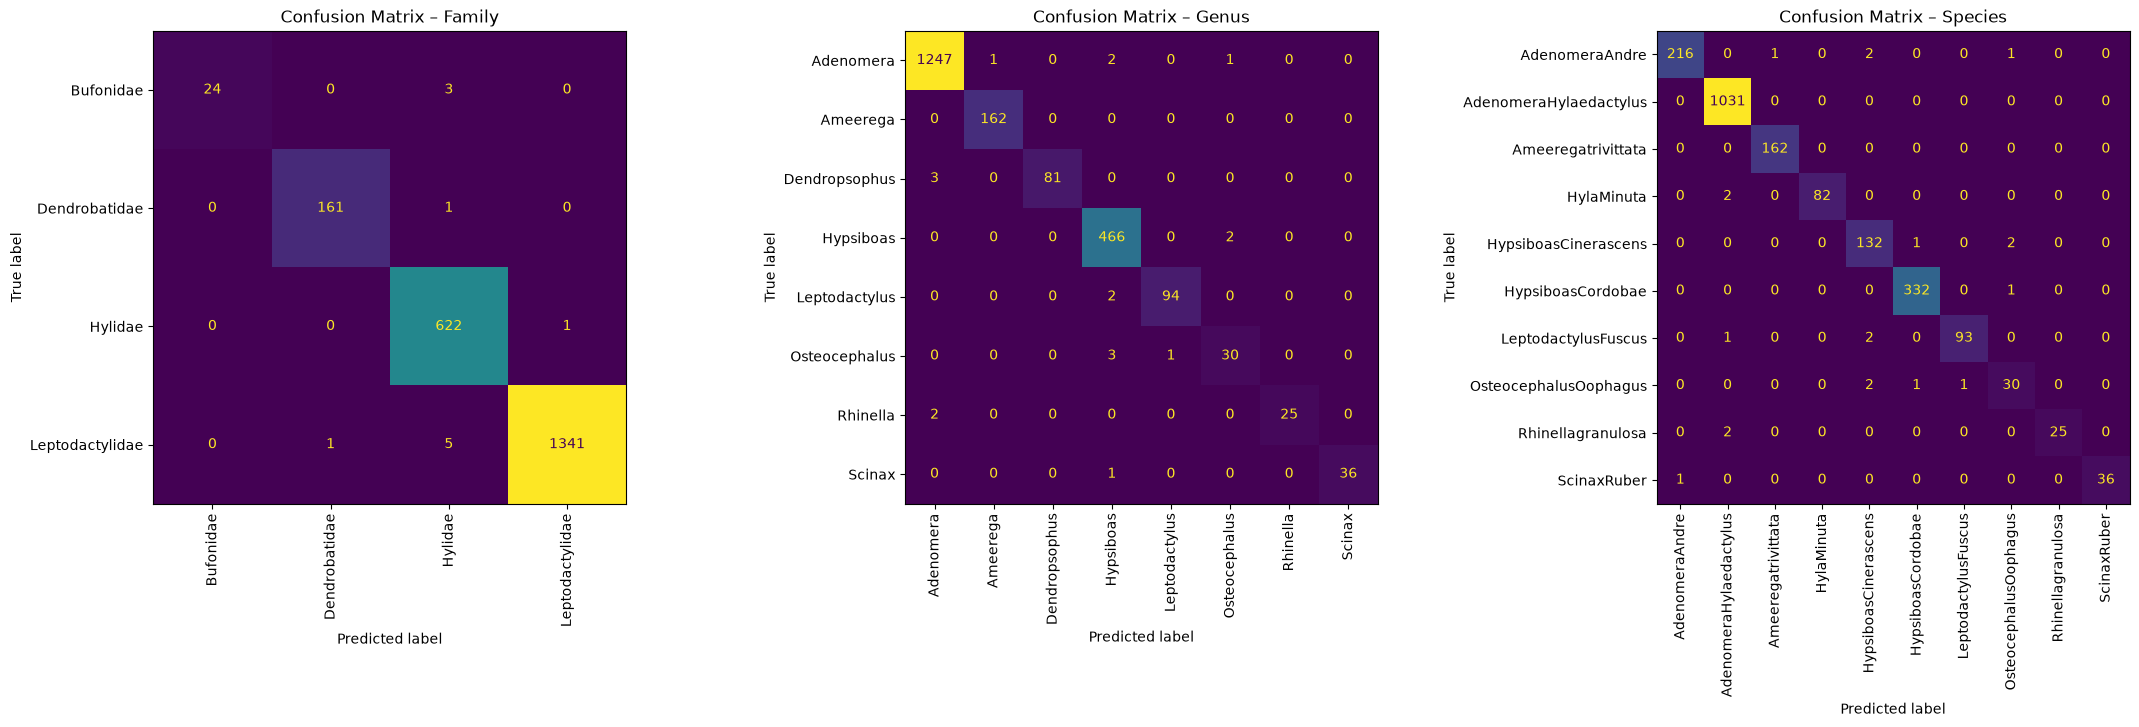

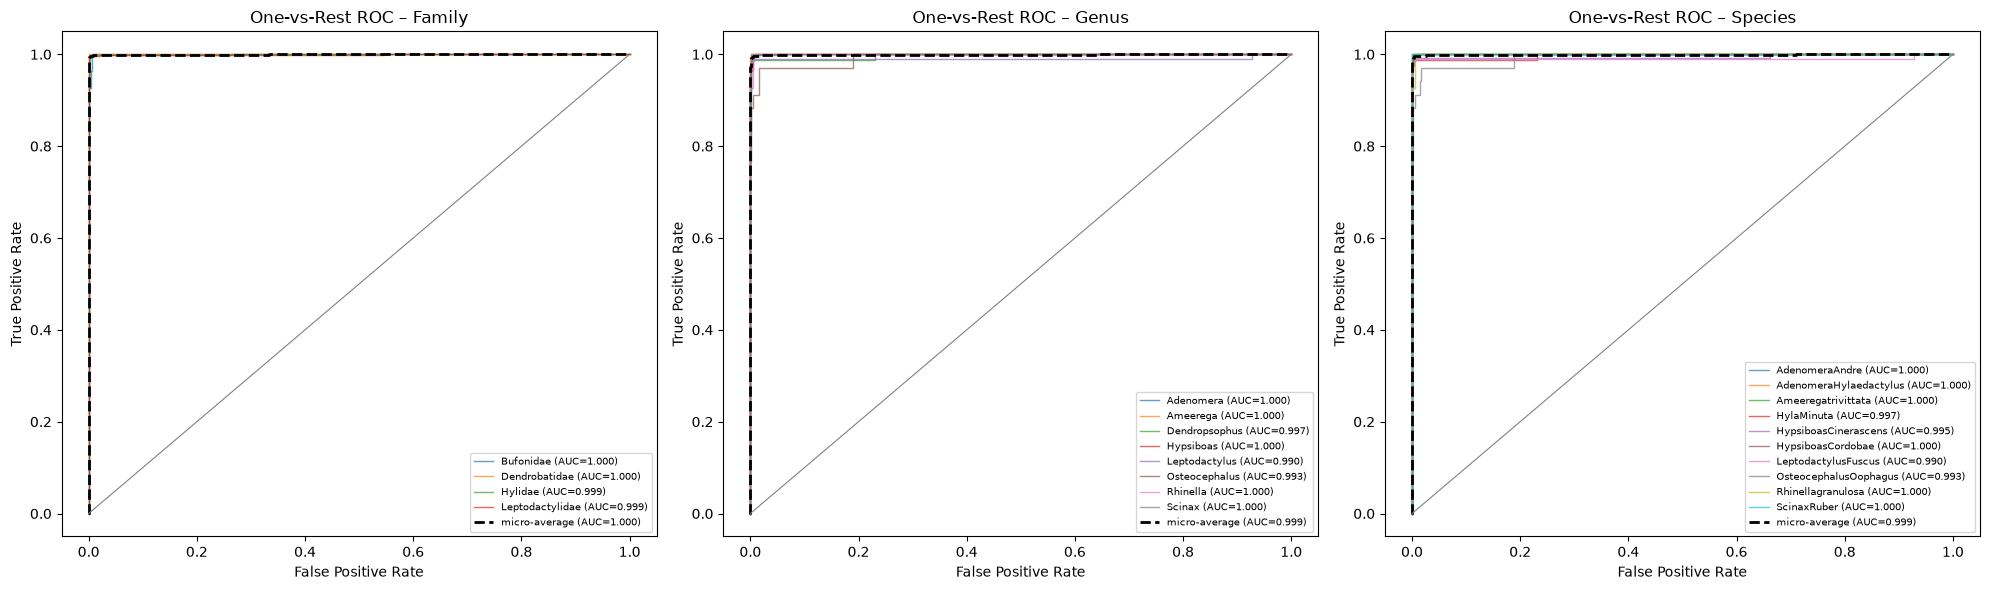

In [11]:
import matplotlib.pyplot as plt

# Confusion matrices and ROC curves for the best model (RBF SVM on raw attributes)
best_models = rbf_models

fig, axes = plt.subplots(1, 3, figsize=(22, 7))
for ax, label in zip(axes, labels):
    ConfusionMatrixDisplay.from_predictions(
        y_test[label], best_models[label].predict(X_test),
        labels=best_models[label].classes_,
        xticks_rotation=90, colorbar=False, ax=ax,
    )
    ax.set_title(f"Confusion Matrix – {label}")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, label in zip(axes, labels):
    model = best_models[label]
    classes = model.classes_
    y_bin = label_binarize(y_test[label], classes=classes)
    scores = model.decision_function(X_test)

    for j, cls in enumerate(classes):
        fpr, tpr, _ = roc_curve(y_bin[:, j], scores[:, j])
        ax.plot(fpr, tpr, lw=1, alpha=0.7,
                label=f"{cls} (AUC={roc_auc_score(y_bin[:, j], scores[:, j]):.3f})")

    fpr, tpr, _ = roc_curve(y_bin.ravel(), scores.ravel())
    ax.plot(fpr, tpr, "k--", lw=2,
            label=f"micro-average (AUC={roc_auc_score(y_bin, scores, average='micro'):.3f})")
    ax.plot([0, 1], [0, 1], color="grey", lw=0.8)
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.set_title(f"One-vs-Rest ROC – {label}")
    ax.legend(fontsize=7, loc="lower right")
plt.tight_layout()
plt.show()

The RBF SVM on raw attributes has macro AUC ≥ 0.997 for every label, and its confusion matrices are almost perfectly diagonal. The few errors are mostly among the minority classes, which is why its macro recall (≈ 0.97) is lower than its accuracy (≈ 0.99).

For the linear models, micro and macro metrics differ much more. The L1 SVM without SMOTE has high micro precision but low macro recall, because it neglects the rare classes. SMOTE raises macro recall (0.78 → 0.92 averaged over the labels) at the cost of macro precision and AUC. In other words, SMOTE moves the decision thresholds in favor of the minority classes rather than improving the ranking of the scores. The AUC measures the ranking, so it does not improve.

## 2. K-Means Clustering on a Multi-Class and Multi-Label Data Set

### 2(a) Selecting the Optimal Number of Clusters

We apply K-Means clustering to the entire Anuran Calls (MFCCs) dataset without a train-test split.

The optimal number of clusters is selected using the Calinski-Harabasz Index. We evaluate k values from 2 to 50 and select the k that maximizes this score. The case k = 1 is excluded from the index calculation because the index requires at least two clusters.

Optimal number of clusters: 2
Best Calinski-Harabasz Score: 3680.7413494630914


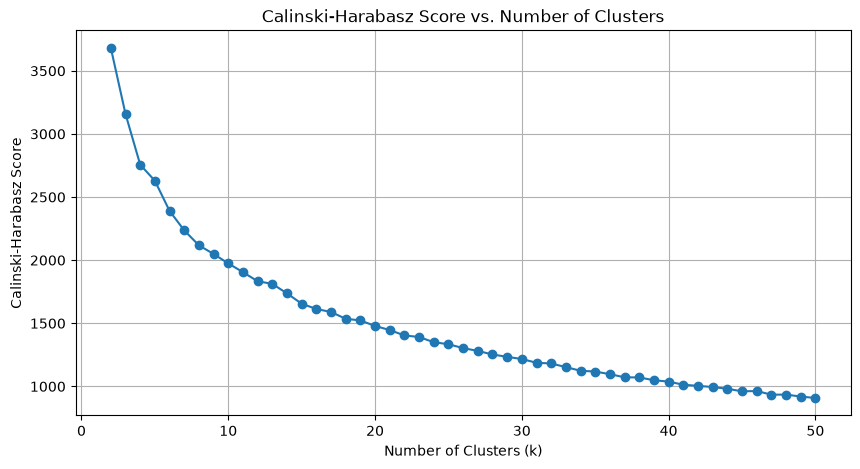

In [12]:
from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score
import matplotlib.pyplot as plt

# Use the entire dataset
X_cluster = df.filter(regex=r"^MFCCs_")

k_values = range(2, 51)
ch_scores = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    cluster_labels = kmeans.fit_predict(X_cluster)

    score = calinski_harabasz_score(
        X_cluster, cluster_labels
    )

    ch_scores.append(score)

best_k = list(k_values)[np.argmax(ch_scores)]

print("Optimal number of clusters:", best_k)
print("Best Calinski-Harabasz Score:", max(ch_scores))

plt.figure(figsize=(10, 5))
plt.plot(list(k_values), ch_scores, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Calinski-Harabasz Score")
plt.title("Calinski-Harabasz Score vs. Number of Clusters")
plt.grid(True)
plt.show()

The Calinski-Harabasz Index reaches its maximum value of 3680.7413 at k = 2. Therefore, k = 2 is selected as the optimal number of clusters.

The score generally decreases as k increases, suggesting that two clusters provide the best separation and compactness according to this criterion.

### 2(b) Determining Majority Labels for Each Cluster

For each cluster, we determine the most frequent Family, Genus, and Species labels based on the true labels of the samples assigned to that cluster.

In [13]:
# Fit K-Means with the selected optimal k
kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

cluster_assignments = kmeans.fit_predict(X_cluster)

# Combine cluster assignments with true labels
cluster_df = df[["Family", "Genus", "Species"]].copy()
cluster_df["Cluster"] = cluster_assignments

# Find majority labels for each cluster
majority_labels = cluster_df.groupby("Cluster")[
    ["Family", "Genus", "Species"]
].agg(lambda x: x.value_counts().idxmax())

print("Majority Labels for Each Cluster:")
display(majority_labels)

Majority Labels for Each Cluster:


,Family,Genus,Species
Cluster,,,
0,Leptodactylidae,Adenomera,AdenomeraHylaedactylus
1,Hylidae,Hypsiboas,HypsiboasCordobae


### 2(c) Hamming Metrics and Monte Carlo Simulation

We assign each sample the majority Family, Genus, and Species labels of its cluster.

We calculate the average Hamming Distance, Hamming Score, and Hamming Loss by comparing the assigned labels with the true labels.

The clustering experiment is repeated 50 times using different random seeds. We report the mean and standard deviation of the 50 average Hamming Distances.

In [14]:
# Assign majority labels to samples based on their clusters
predicted_labels = majority_labels.loc[
    cluster_assignments
].reset_index(drop=True)

true_labels = df[
    ["Family", "Genus", "Species"]
].reset_index(drop=True)

# Number of mismatched labels per sample
hamming_distances = (
    true_labels.to_numpy() != predicted_labels.to_numpy()
).sum(axis=1)

# Calculate Hamming metrics
avg_hamming_distance = hamming_distances.mean()
hamming_loss_value = avg_hamming_distance / 3
hamming_score_value = 1 - hamming_loss_value

print(f"Average Hamming Distance: {avg_hamming_distance:.4f}")
print(f"Hamming Score: {hamming_score_value:.4f}")
print(f"Hamming Loss: {hamming_loss_value:.4f}")

Average Hamming Distance: 0.8956
Hamming Score: 0.7015
Hamming Loss: 0.2985


In [15]:
# Monte Carlo Simulation: 50 repetitions
mc_distances = []
mc_scores = []
mc_losses = []
mc_best_ks = []

true_array = true_labels.to_numpy()

for seed in range(50):
    # Select optimal k for each repetition
    scores = []

    for k in range(2, 51):
        km = KMeans(
            n_clusters=k,
            random_state=seed,
            n_init=10
        )

        labels_k = km.fit_predict(X_cluster)
        score = calinski_harabasz_score(X_cluster, labels_k)
        scores.append(score)

    optimal_k = np.argmax(scores) + 2
    mc_best_ks.append(optimal_k)

    # Fit K-Means using the selected k
    km = KMeans(
        n_clusters=optimal_k,
        random_state=seed,
        n_init=10
    )

    assignments = km.fit_predict(X_cluster)

    temp_df = true_labels.copy()
    temp_df["Cluster"] = assignments

    # Majority labels
    majority = temp_df.groupby("Cluster")[
        ["Family", "Genus", "Species"]
    ].agg(lambda x: x.value_counts().idxmax())

    predictions = majority.loc[assignments].to_numpy()

    # Hamming metrics
    distance = np.mean(
        np.sum(true_array != predictions, axis=1)
    )

    mc_distances.append(distance)
    mc_losses.append(distance / 3)
    mc_scores.append(1 - distance / 3)

mc_summary = pd.DataFrame({
    "Mean": [np.mean(mc_distances), np.mean(mc_scores), np.mean(mc_losses)],
    "Std": [np.std(mc_distances), np.std(mc_scores), np.std(mc_losses)],
}, index=["Hamming Distance", "Hamming Score", "Hamming Loss"])

print("Monte Carlo Simulation Results (50 repetitions):")
display(mc_summary.round(6))

print("\nSelected k values:")
print(pd.Series(mc_best_ks).value_counts().sort_index())

Monte Carlo Simulation Results (50 repetitions):


,Mean,Std
Hamming Distance,0.895622,0.0
Hamming Score,0.701459,0.0
Hamming Loss,0.298541,0.0



Selected k values:
2    50
Name: count, dtype: int64


### 2(d) Conclusions

The Calinski-Harabasz Index selected k = 2 as the optimal number of clusters in all 50 Monte Carlo repetitions.

The mean Hamming Distance was 0.895622, with a standard deviation of 0.000000. The mean Hamming Score was 0.701459 and the mean Hamming Loss was 0.298541, both also with a standard deviation of 0.000000.

**Why the standard deviation is zero.** Each repetition uses a different random seed, but every K-Means fit uses `n_init=10`: it runs 10 random initializations and keeps the one with the lowest within-cluster sum of squares. With k = 2 the dataset has one clearly dominant two-cluster split, so all 50 runs converge to the same partition (up to relabeling of the clusters). The same partition gives the same majority-label triplets and therefore exactly the same Hamming distance. The zero standard deviation shows that the procedure is stable; it does not mean the seeds were ignored.

The relatively high Hamming Loss (about 0.30) shows that the two clusters do not match the true labels well. With only two clusters, each sample can be assigned only one of two (Family, Genus, Species) triplets, but the data contain 4 families, 8 genera and 10 species. Most samples from minority classes are therefore mislabeled at least at the genus and species level.

## 3. ISLR 12.6.2 – Hierarchical Clustering

### 3(a) Complete Linkage Clustering

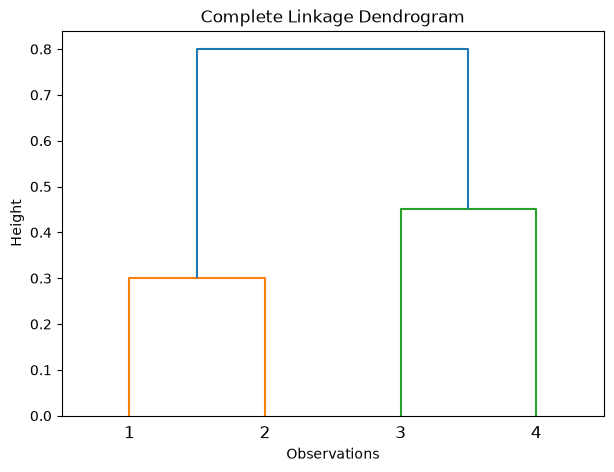

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram

# Condensed dissimilarity matrix
distances = [0.3, 0.4, 0.7, 0.5, 0.8, 0.45]

# Complete linkage
Z_complete = linkage(distances, method="complete")

plt.figure(figsize=(7, 5))
dendrogram(
    Z_complete,
    labels=["1", "2", "3", "4"]
)

plt.title("Complete Linkage Dendrogram")
plt.xlabel("Observations")
plt.ylabel("Height")
plt.show()

Using complete linkage, observations 1 and 2 are merged at height 0.30, and observations 3 and 4 are merged at height 0.45. Finally, the two clusters are merged at height 0.80.

### 3(b) Single Linkage Clustering

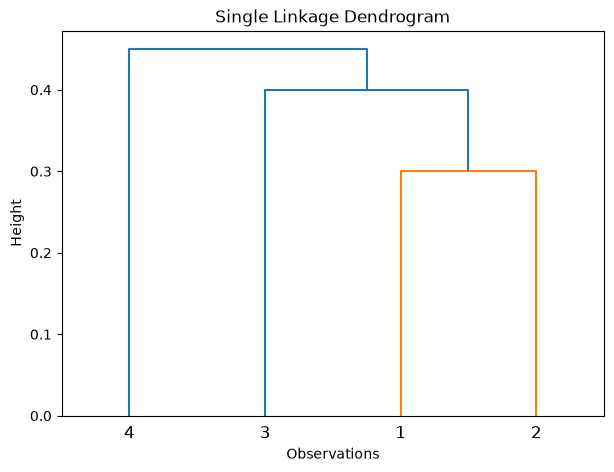

In [17]:
# Single linkage
Z_single = linkage(distances, method="single")

plt.figure(figsize=(7, 5))
dendrogram(
    Z_single,
    labels=["1", "2", "3", "4"]
)

plt.title("Single Linkage Dendrogram")
plt.xlabel("Observations")
plt.ylabel("Height")
plt.show()

Using single linkage, observations 1 and 2 are first merged at height 0.30. Observation 3 then joins the cluster at height 0.40. Finally, observation 4 joins the cluster at height 0.45.

### 3(c) Two Clusters Using Complete Linkage

When the complete linkage dendrogram is cut to obtain two clusters, the resulting groups are:

- Cluster 1: Observations 1 and 2
- Cluster 2: Observations 3 and 4

### 3(d) Two Clusters Using Single Linkage

When the single linkage dendrogram is cut to obtain two clusters, the resulting groups are:

- Cluster 1: Observations 1, 2, and 3
- Cluster 2: Observation 4

### 3(e) Equivalent Complete Linkage Dendrogram

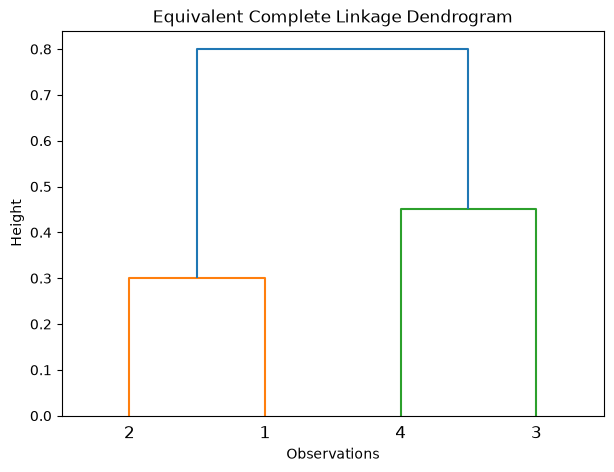

In [18]:
# Swap the leaf positions while preserving merge heights
Z_equivalent = Z_complete.copy()

Z_equivalent[0, 0], Z_equivalent[0, 1] = (
    Z_equivalent[0, 1], Z_equivalent[0, 0]
)

Z_equivalent[1, 0], Z_equivalent[1, 1] = (
    Z_equivalent[1, 1], Z_equivalent[1, 0]
)

plt.figure(figsize=(7, 5))
dendrogram(
    Z_equivalent,
    labels=["1", "2", "3", "4"]
)

plt.title("Equivalent Complete Linkage Dendrogram")
plt.xlabel("Observations")
plt.ylabel("Height")
plt.show()

The positions of observations 1 and 2, as well as observations 3 and 4, have been swapped.

The clustering structure and merge heights remain unchanged (0.30, 0.45, and 0.80). Therefore, the new dendrogram is equivalent to the original complete linkage dendrogram.